Installation & Setup

In [ ]:
!pip install -q spacy sentence-transformers matplotlib seaborn pandas
!python -m spacy download en_core_web_sm
print("Setup completed successfully!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 47.6 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
Setup completed successfully!


Define a Story-Based Corpus

In [ ]:
story_sentences = [
    "The fierce lion chased the frightened rabbit through the dense forest.",
    "A clever fox outsmarted the greedy wolf near the riverbank.",
    "The young girl picked bright red strawberries in the sunny garden.",
    "A tiny mouse saved the sleeping lion from the heavy hunter's net.",
    "The wise owl warned all the forest animals about the upcoming winter storm."
]

print(f"Loaded {len(story_sentences)} sentences from the story corpus:\n")
for i, s in enumerate(story_sentences, 1):
    print(f"[Sentence {i}]: {s}")

Loaded 5 sentences from the story corpus:

[Sentence 1]: The fierce lion chased the frightened rabbit through the dense forest.
[Sentence 2]: A clever fox outsmarted the greedy wolf near the riverbank.
[Sentence 3]: The young girl picked bright red strawberries in the sunny garden.
[Sentence 4]: A tiny mouse saved the sleeping lion from the heavy hunter's net.
[Sentence 5]: The wise owl warned all the forest animals about the upcoming winter storm.


Sentence Meaning (Who did what to whom)

In [ ]:

import spacy
import pandas as pd

nlp = spacy.load("en_core_web_sm")

def extract_semantic_roles(sentences):
    records = []
    for idx, text in enumerate(sentences, 1):
        doc = nlp(text)
        subject = "N/A"
        verb = "N/A"
        object_ = "N/A"

        for token in doc:
            # Identify main predicate verb
            if token.pos_ == "VERB" and token.dep_ in ("ROOT", "conj"):
                verb = token.text
                # Find subject (nsubj)
                for child in token.children:
                    if child.dep_ == "nsubj":
                        subject = " ".join([w.text for w in child.subtree])
                    # Find direct object or prepositional object (dobj, pobj, attr)
                    if child.dep_ in ("dobj", "pobj", "attr"):
                        object_ = " ".join([w.text for w in child.subtree])

        records.append({
            "ID": f"S{idx}",
            "Sentence": text,
            "Who (Subject)": subject,
            "Action (Verb)": verb,
            "Whom/What (Object)": object_
        })

    return pd.DataFrame(records)

df_roles = extract_semantic_roles(story_sentences)
# Display formatted table in Colab
df_roles.style.set_caption("Semantic Role Analysis: Who Did What to Whom")

,ID,Sentence,Who (Subject),Action (Verb),Whom/What (Object)
0,S1,The fierce lion chased the frightened rabbit through the dense forest.,The fierce lion,chased,the frightened rabbit
1,S2,A clever fox outsmarted the greedy wolf near the riverbank.,A clever fox,outsmarted,the greedy wolf
2,S3,The young girl picked bright red strawberries in the sunny garden.,The young girl,picked,bright red strawberries
3,S4,A tiny mouse saved the sleeping lion from the heavy hunter's net.,A tiny mouse,saved,the sleeping lion from the heavy hunter 's net
4,S5,The wise owl warned all the forest animals about the upcoming winter storm.,The wise owl,warned,all the forest animals


Sentence Similarity Analysis

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Cosine Similarity Matrix:


,S1,S2,S3,S4,S5
S1,1.000000,0.327289,0.051087,0.300151,0.354988
S2,0.327289,1.000000,0.088652,0.425621,0.351856
S3,0.051087,0.088652,1.000000,-0.012402,0.047862
S4,0.300151,0.425621,-0.012402,1.000000,0.354923
S5,0.354988,0.351856,0.047862,0.354923,1.000000


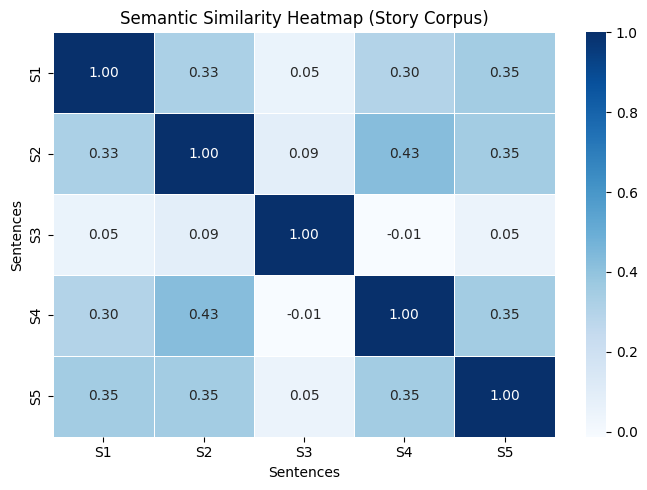

In [ ]:
from sentence_transformers import SentenceTransformer, util
import matplotlib.pyplot as plt
import seaborn as sns

# Load pretrained transformer model
model = SentenceTransformer('all-MiniLM-L6-v2')

# Generate sentence embeddings
embeddings = model.encode(story_sentences, convert_to_tensor=True)

# Compute cosine similarity matrix
cosine_matrix = util.cos_sim(embeddings, embeddings).cpu().numpy()

# Format into a DataFrame
labels = [f"S{i}" for i in range(1, len(story_sentences) + 1)]
df_similarity = pd.DataFrame(cosine_matrix, index=labels, columns=labels)

print("Cosine Similarity Matrix:")
display(df_similarity)

# Plot Heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(df_similarity, annot=True, cmap="Blues", fmt=".2f", linewidths=.5,
            xticklabels=labels, yticklabels=labels)
plt.title("Semantic Similarity Heatmap (Story Corpus)")
plt.xlabel("Sentences")
plt.ylabel("Sentences")
plt.tight_layout()
plt.show()

Pairwise Semantic Comparison & Report

In [ ]:
# Cell 5: Detailed Pairwise Similarity Analysis
idx_a = 0  # "The fierce lion chased..."
idx_b = 3  # "A tiny mouse saved the sleeping lion..."

sent_a = story_sentences[idx_a]
sent_b = story_sentences[idx_b]

emb_a = model.encode(sent_a, convert_to_tensor=True)
emb_b = model.encode(sent_b, convert_to_tensor=True)

score = util.cos_sim(emb_a, emb_b).item()

print(f"Comparing Sentence 1 and Sentence 4:\n")
print(f"• Sentence A: {sent_a}")
print(f"• Sentence B: {sent_b}")
print(f"\nCosine Similarity Score: {score:.4f}")
print("\nAnalysis Insight:")
print("Although both sentences feature the entity 'lion', they describe completely different actions and events (chasing a rabbit vs. being saved by a mouse), which is reflected in a moderate similarity score driven primarily by shared vocabulary rather than identical narrative roles.")

Comparing Sentence 1 and Sentence 4:

• Sentence A: The fierce lion chased the frightened rabbit through the dense forest.
• Sentence B: A tiny mouse saved the sleeping lion from the heavy hunter's net.

Cosine Similarity Score: 0.3002

Analysis Insight:
Although both sentences feature the entity 'lion', they describe completely different actions and events (chasing a rabbit vs. being saved by a mouse), which is reflected in a moderate similarity score driven primarily by shared vocabulary rather than identical narrative roles.
